# Import libraries

In [3]:
from google.colab import drive
import os
import cv2
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import accuracy_score, confusion_matrix

# Load the data from drive

In [4]:
drive.mount('/content/drive')
!cp -r "/content/drive/MyDrive/Fruits_Project_Data" /content/Fruits_Project_Data
base_dir = "/content/drive/MyDrive/Fruits_Project_Data"
train_dir = os.path.join(base_dir, "Training")
test_dir = os.path.join(base_dir, "Test")

Mounted at /content/drive


In [5]:
classes = sorted(os.listdir(train_dir))
print("classes list: ", list(enumerate(classes)))

def load_data(folder_path, classes_list, img_size=(64, 64)):
    X = []
    y = []

    for label_idx, class_name in enumerate(classes_list):
        class_folder = os.path.join(folder_path, class_name)
        for img_name in os.listdir(class_folder):
            img_path = os.path.join(class_folder, img_name)
            img = cv2.imread(img_path)
            if img is None:
              continue

            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img = cv2.resize(img, img_size)
            img = img / 255.0
            img = img.flatten()

            X.append(img)
            y.append(label_idx)

    return np.array(X), np.array(y)

X_train, y_train = load_data(train_dir, classes)
X_test, y_test = load_data(test_dir, classes)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

classes list:  [(0, 'Apple Red 1'), (1, 'Avocado 1'), (2, 'Orange 1'), (3, 'Strawberry 1'), (4, 'Watermelon 1')]
X_train shape: (2365, 12288)
y_train shape: (2365,)
X_test shape: (788, 12288)
y_test shape: (788,)


# We look at the count of each class

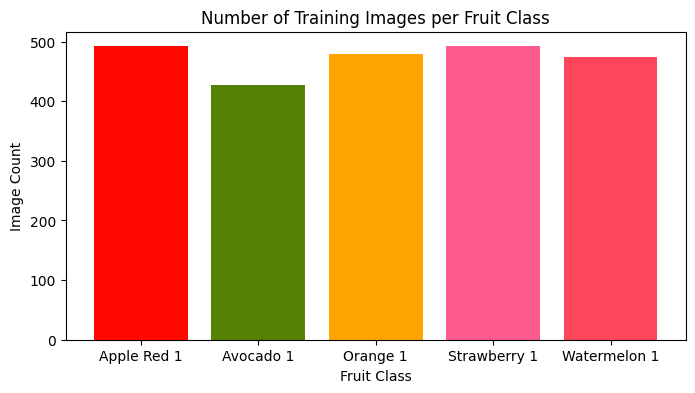

In [6]:
unique_labels, counts = np.unique(y_train, return_counts=True)
plt.figure(figsize=(8, 4))
plt.bar(classes, counts, color=['#FF0800', '#568203', '#FFA500', '#FC5A8D', '#FD4659'])
plt.title("Number of Training Images per Fruit Class")
plt.xlabel("Fruit Class")
plt.ylabel("Image Count")
plt.show()

# Show one photo of every class

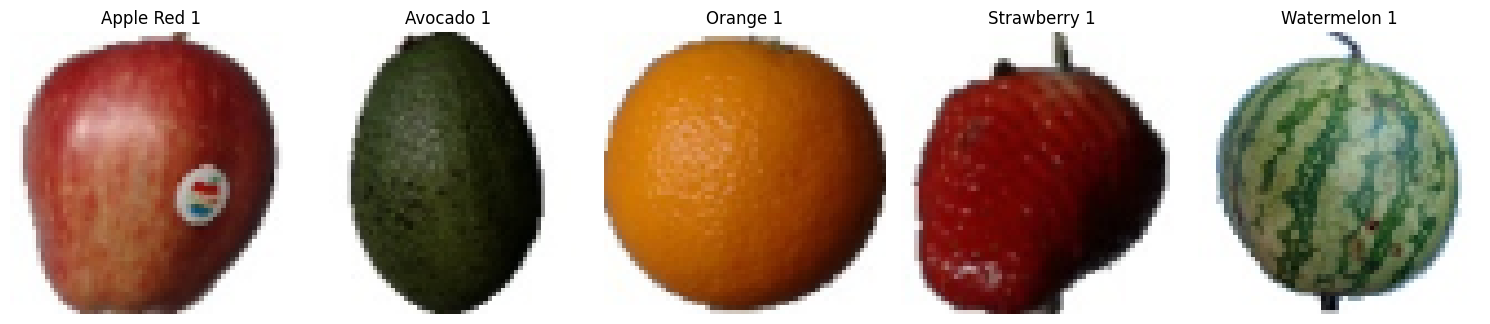

In [7]:
fig, axes = plt.subplots(1, len(classes), figsize=(15, 4))

for idx, class_name in enumerate(classes):
    first_img_idx = np.where(y_train == idx)[0][0]

    img_reshaped = X_train[first_img_idx].reshape(64, 64, 3)

    axes[idx].imshow(img_reshaped)
    axes[idx].set_title(class_name)
    axes[idx].axis("off")

plt.tight_layout()
plt.show()

# Train the model

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA

X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=42
)

pca = PCA(n_components=100, random_state=42)
X_train_pca = pca.fit_transform(X_train_sub)
X_val_pca = pca.transform(X_val)
X_test_pca = pca.transform(X_test)

print("X_train_pca shape:", X_train_pca.shape)
print("X_val_pca shape:", X_val_pca.shape)
print("X_test_pca shape:", X_test_pca.shape)

X_train_pca shape: (1892, 100)
X_val_pca shape: (473, 100)
X_test_pca shape: (788, 100)


# Logistic Regression

In [19]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

C_values = [0.01, 0.05, 0.1, 0.5, 1, 10, 100]
best_c = None
best_val_acc_lr = 0

print("Tuning Logistic Regression (C):")
for c in C_values:
    lr = LogisticRegression(C=c, max_iter=1000, random_state=42)
    lr.fit(X_train_pca, y_train_sub)

    val_preds = lr.predict(X_val_pca)
    val_acc = accuracy_score(y_val, val_preds)
    print(f"C = {c:<6} -> Validation Accuracy: {val_acc:.4f}")

    if val_acc > best_val_acc_lr:
        best_val_acc_lr = val_acc
        best_c = c

print(f"\nBest C for Logistic Regression: {best_c} | Validation Accuracy: {best_val_acc_lr:.4f}")

best_lr = LogisticRegression(C=best_c, max_iter=1000, random_state=42)
best_lr.fit(X_train_pca, y_train_sub)

Tuning Logistic Regression (C):
C = 0.01   -> Validation Accuracy: 1.0000
C = 0.05   -> Validation Accuracy: 1.0000
C = 0.1    -> Validation Accuracy: 1.0000
C = 0.5    -> Validation Accuracy: 1.0000
C = 1      -> Validation Accuracy: 1.0000
C = 10     -> Validation Accuracy: 1.0000
C = 100    -> Validation Accuracy: 1.0000

Best C for Logistic Regression: 0.01 | Validation Accuracy: 1.0000


LogisticRegression(C=0.01, max_iter=1000, random_state=42)

In [10]:
lr_test_pred = best_lr.predict(X_test_pca)

lr_test_acc = accuracy_score(y_test, lr_test_pred)
print(lr_test_acc)

1.0


# KNN

In [18]:
from sklearn.neighbors import KNeighborsClassifier

k_values = [1, 3, 5, 7, 9]
best_k = None
best_val_acc_knn = 0

print("Tuning KNN Classifier (n_neighbors):")
for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_pca, y_train_sub)

    val_preds = knn.predict(X_val_pca)
    val_acc = accuracy_score(y_val, val_preds)
    print(f"k = {k:<3} -> Validation Accuracy: {val_acc:.4f}")

    if val_acc > best_val_acc_knn:
        best_val_acc_knn = val_acc
        best_k = k

print(f"\nBest k for KNN: {best_k} | Validation Accuracy: {best_val_acc_knn:.4f}")

best_knn = KNeighborsClassifier(n_neighbors=best_k)
best_knn.fit(X_train_pca, y_train_sub)

Tuning KNN Classifier (n_neighbors):
k = 1   -> Validation Accuracy: 1.0000
k = 3   -> Validation Accuracy: 1.0000
k = 5   -> Validation Accuracy: 1.0000
k = 7   -> Validation Accuracy: 1.0000
k = 9   -> Validation Accuracy: 1.0000

Best k for KNN: 1 | Validation Accuracy: 1.0000


KNeighborsClassifier(n_neighbors=1)

In [12]:
knn_test_pred = best_knn.predict(X_test_pca)

knn_test_acc = accuracy_score(y_test, knn_test_pred)

print(knn_test_acc)

0.9974619289340102


# Confusion matrix for logisitc regression and knn

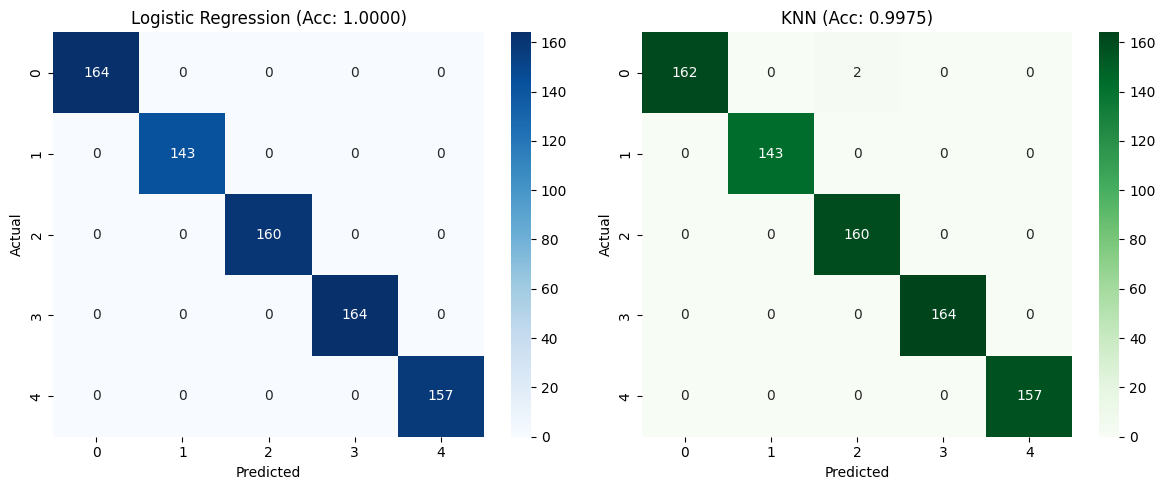

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(confusion_matrix(y_test, lr_test_pred), annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title(f'Logistic Regression (Acc: {lr_test_acc:.4f})')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

sns.heatmap(confusion_matrix(y_test, knn_test_pred), annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title(f'KNN (Acc: {knn_test_acc:.4f})')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()

# K-means

In [14]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

km = KMeans(n_clusters=5, random_state=42)
km.fit(X_train_pca)

km_train_pred = km.predict(X_train_pca)
km_val_pred = km.predict(X_val_pca)
km_test_pred = km.predict(X_test_pca)

cluster_to_label = {}
for id in range(5):
  labels = y_train_sub[km_train_pred == id]
  most_frequent_label = np.bincount(labels).argmax()
  cluster_to_label[id] = most_frequent_label

km_train_mapped = np.array([cluster_to_label[c] for c in km_train_pred])
km_val_mapped = np.array([cluster_to_label[c] for c in km_val_pred])
km_test_mapped = np.array([cluster_to_label[c] for c in km_test_pred])

print("Train accuracy:", accuracy_score(y_train_sub, km_train_mapped))
print("Validation accuracy:", accuracy_score(y_val, km_val_mapped))
print("Test accuracy:", accuracy_score(y_test, km_test_mapped))
print("Test silhouette score:", silhouette_score(X_test_pca, km_test_pred))

Train accuracy: 0.6807610993657506
Validation accuracy: 0.7167019027484144
Test accuracy: 0.6878172588832487
Test silhouette score: 0.3429400178440593


# Decision Tree

max_depth = 2     -> Validation Accuracy: 0.5899
max_depth = 4     -> Validation Accuracy: 0.9493
max_depth = 6     -> Validation Accuracy: 0.9958
max_depth = 8     -> Validation Accuracy: 0.9958
max_depth = 10    -> Validation Accuracy: 0.9958
max_depth = 15    -> Validation Accuracy: 0.9958
max_depth = None  -> Validation Accuracy: 0.9958

Best max_depth: 6 | Validation Accuracy: 0.9958
Test Accuracy: 0.9239


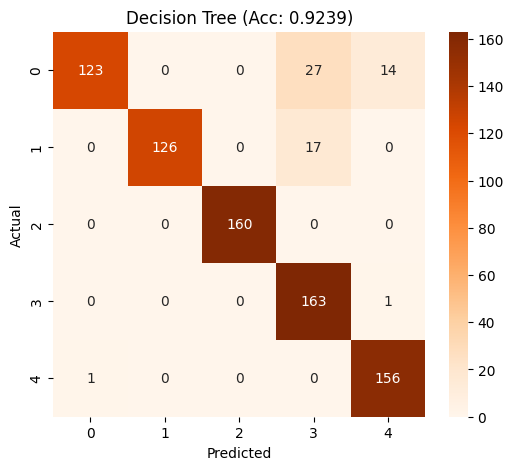

In [15]:
from sklearn.tree import DecisionTreeClassifier

max_depth_values = [2, 4, 6, 8, 10, 15, None]
best_depth = None
best_val_acc_dt = 0

for depth in max_depth_values:
    dt = DecisionTreeClassifier(max_depth=depth, random_state=42)
    dt.fit(X_train_pca, y_train_sub)
    val_preds = dt.predict(X_val_pca)
    val_acc = accuracy_score(y_val, val_preds)
    print(f"max_depth = {str(depth):<5} -> Validation Accuracy: {val_acc:.4f}")
    if val_acc > best_val_acc_dt:
        best_val_acc_dt = val_acc
        best_depth = depth

print(f"\nBest max_depth: {best_depth} | Validation Accuracy: {best_val_acc_dt:.4f}")

best_dt = DecisionTreeClassifier(max_depth=best_depth, random_state=42)
best_dt.fit(X_train_pca, y_train_sub)

dt_test_pred = best_dt.predict(X_test_pca)
dt_test_acc = accuracy_score(y_test, dt_test_pred)
print(f"Test Accuracy: {dt_test_acc:.4f}")

plt.figure(figsize=(6, 5))
sns.heatmap(confusion_matrix(y_test, dt_test_pred), annot=True, fmt='d', cmap='Oranges')
plt.title(f'Decision Tree (Acc: {dt_test_acc:.4f})')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# Random Forest Classifier


n_estimators = 50   | max_depth = 4     -> Validation Accuracy: 1.0000
n_estimators = 50   | max_depth = 6     -> Validation Accuracy: 1.0000
n_estimators = 50   | max_depth = 10    -> Validation Accuracy: 1.0000
n_estimators = 50   | max_depth = None  -> Validation Accuracy: 1.0000
n_estimators = 100  | max_depth = 4     -> Validation Accuracy: 1.0000
n_estimators = 100  | max_depth = 6     -> Validation Accuracy: 1.0000
n_estimators = 100  | max_depth = 10    -> Validation Accuracy: 1.0000
n_estimators = 100  | max_depth = None  -> Validation Accuracy: 1.0000
n_estimators = 200  | max_depth = 4     -> Validation Accuracy: 0.9979
n_estimators = 200  | max_depth = 6     -> Validation Accuracy: 1.0000
n_estimators = 200  | max_depth = 10    -> Validation Accuracy: 1.0000
n_estimators = 200  | max_depth = None  -> Validation Accuracy: 1.0000

Best Params -> n_estimators: 50, max_depth: 4 | Validation Accuracy: 1.0000
Test Accuracy: 0.9975


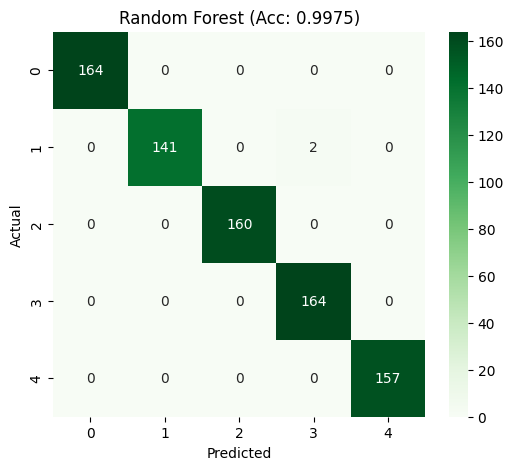

In [16]:
from sklearn.ensemble import RandomForestClassifier

n_estimators_values = [50, 100, 200]
max_depth_values_rf = [4, 6, 10, None]

best_params_rf = None
best_val_acc_rf = 0

for n_est in n_estimators_values:
    for depth in max_depth_values_rf:
        rf = RandomForestClassifier(n_estimators=n_est, max_depth=depth, random_state=42, n_jobs=-1)
        rf.fit(X_train_pca, y_train_sub)
        val_preds = rf.predict(X_val_pca)
        val_acc = accuracy_score(y_val, val_preds)
        print(f"n_estimators = {n_est:<4} | max_depth = {str(depth):<5} -> Validation Accuracy: {val_acc:.4f}")
        if val_acc > best_val_acc_rf:
            best_val_acc_rf = val_acc
            best_params_rf = (n_est, depth)

print(f"\nBest Params -> n_estimators: {best_params_rf[0]}, max_depth: {best_params_rf[1]} | Validation Accuracy: {best_val_acc_rf:.4f}")

best_rf = RandomForestClassifier(
    n_estimators=best_params_rf[0],
    max_depth=best_params_rf[1],
    random_state=42,
    n_jobs=-1
)
best_rf.fit(X_train_pca, y_train_sub)

rf_test_pred = best_rf.predict(X_test_pca)
rf_test_acc = accuracy_score(y_test, rf_test_pred)
print(f"Test Accuracy: {rf_test_acc:.4f}")

plt.figure(figsize=(6, 5))
sns.heatmap(confusion_matrix(y_test, rf_test_pred), annot=True, fmt='d', cmap='Greens')
plt.title(f'Random Forest (Acc: {rf_test_acc:.4f})')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# Ensemble Model (Voting & Stacking)

                 Model  Test Accuracy
   Logistic Regression       1.000000
                   KNN       0.997462
         Decision Tree       0.923858
         Random Forest       0.997462
Voting Ensemble (Soft)       0.998731
     Stacking Ensemble       0.997462


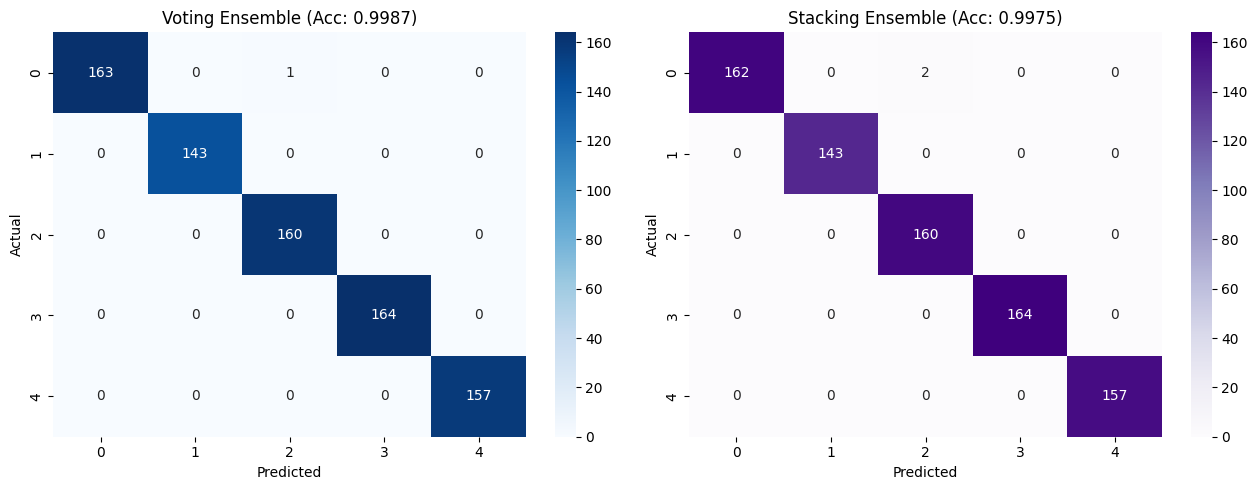

In [17]:
from sklearn.ensemble import VotingClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
import pandas as pd

estimators = [
    ('lr', best_lr),
    ('knn', best_knn),
    ('rf', best_rf)
]

voting_clf = VotingClassifier(estimators=estimators, voting='soft')
voting_clf.fit(X_train_pca, y_train_sub)
voting_test_pred = voting_clf.predict(X_test_pca)
voting_test_acc = accuracy_score(y_test, voting_test_pred)

stacking_clf = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression(max_iter=1000, random_state=42),
    cv=5
)
stacking_clf.fit(X_train_pca, y_train_sub)
stacking_test_pred = stacking_clf.predict(X_test_pca)
stacking_test_acc = accuracy_score(y_test, stacking_test_pred)

results_df = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'KNN',
        'Decision Tree',
        'Random Forest',
        'Voting Ensemble (Soft)',
        'Stacking Ensemble'
    ],
    'Test Accuracy': [
        accuracy_score(y_test, best_lr.predict(X_test_pca)),
        accuracy_score(y_test, best_knn.predict(X_test_pca)),
        dt_test_acc,
        rf_test_acc,
        voting_test_acc,
        stacking_test_acc
    ]
})

print(results_df.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.heatmap(confusion_matrix(y_test, voting_test_pred), annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title(f'Voting Ensemble (Acc: {voting_test_acc:.4f})')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

sns.heatmap(confusion_matrix(y_test, stacking_test_pred), annot=True, fmt='d', cmap='Purples', ax=axes[1])
axes[1].set_title(f'Stacking Ensemble (Acc: {stacking_test_acc:.4f})')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()

## Model Evaluation & Comparison Summary

### 1. Final Test Results (788 Test Samples)

| Model | Key Hyperparameters | Validation Accuracy | Test Accuracy | Misclassified Samples |
| :--- | :--- | :---: | :---: | :---: |
| **Logistic Regression** | Tuned Linear Classifier | — | **1.0000** | 0 / 788 |
| **Voting Ensemble (Soft)** | `LR + KNN + RF` | — | **0.9987** | 1 / 788 |
| **Stacking Ensemble** | `LR + KNN + RF` (Meta: `LR`, `cv=5`) | — | **0.9975** | 2 / 788 |
| **Random Forest** | `n_estimators=50`, `max_depth=4` | 1.0000 | **0.9975** | 2 / 788 |
| **KNN** | Tuned $k$ | — | **0.9975** | 2 / 788 |
| **Decision Tree** | `max_depth=6` | 0.9958 | **0.9239** | 60 / 788 |

### 2. Key Observations & Analysis

* **Effect of Tree Depth (`Decision Tree`):** At `max_depth=2`, the model suffered from severe **underfitting** (`0.5899` validation accuracy). Increasing depth to `6` reached peak validation accuracy (`0.9958`), beyond which performance plateaued. However, test accuracy dropped to `0.9239` due to **high variance** from axis-aligned splits on continuous PCA components.
* **Bagging Impact (`Random Forest`):** Aggregating 50 shallow trees (`max_depth=4`) eliminated the variance of a single tree, boosting test accuracy from `0.9239` to `0.9975` with only 2 misclassified samples.
* **Ensemble Performance (`Voting` & `Stacking`):** Combining diverse model families (`Logistic Regression`, `KNN`, and `Random Forest`) produced strong generalization. **Soft Voting** reached `0.9987` test accuracy (only 1 error), outperforming every individual tree-based and distance-based model.
* **Linear Separability in PCA Space:** `Logistic Regression` achieved `1.0000` test accuracy because projecting the $64 \times 64$ images onto the top 100 principal components produced orthogonal features with clean linear decision boundaries.